# PathSnap — Julia's MLP Model (Model 6)

**Reference used:** the uploaded `pathsnap-main` repository ZIP, especially its current `TEAM.md`, `src/features.py`, `src/evaluate.py`, `src/config.py`, `src/build_dataset.py`, and `README.md`.

**Owner:** Julia — Member 4  
**Model:** Model 6 — Multi-Layer Perceptron (MLP)  
**Environment:** Google Colab

This notebook is adapted to the repository you uploaded, rather than assuming a different project layout.

### What this notebook does
1. Loads the actual PathSnap repository and its included `data/train` and `data/student_test` trips.
2. Builds candidate and fix tables using the repository's `src.build_dataset`.
3. Builds features using the repository's `src.features`.
4. Trains an MLP using epoch-by-epoch `partial_fit`.
5. Uses 5-fold `GroupKFold` by `trip_id`, following `src.evaluate`.
6. Records training and validation log loss after every epoch.
7. Evaluates on the 10 `student_test` trips using the shared evaluation functions.
8. Saves the model, metrics, configuration, loss histories and plots under the repository's `results/models/mlp/` and `artifacts/`.

**No results are pre-filled or fabricated.** All metrics and curves are produced by running the experiments.

## 0. Important repository-specific notes

The uploaded repository already contains:
- `src/config.py`
- `src/data_io.py`
- `src/geo.py`
- `src/network.py`
- `src/labels.py`
- `src/candidates.py`
- `src/build_dataset.py`
- `src/features.py`
- `src/evaluate.py`

The feature module defines the authoritative `FEATURE_COLUMNS` list (19 features) and adds `arc_u` / `arc_v` as metadata for route-continuity evaluation. The evaluation module provides `group_folds`, `evaluate_predictions`, `training_rows` and the shared metrics.

The uploaded repository snapshot does **not** currently contain `src/model_zoo.py` or `src/train.py`. This notebook therefore runs Julia's MLP experiment using the existing shared data and evaluation code. It does not invent or overwrite those missing team files. After the team adds the common runner, the MLP can be registered there in coordination with Krishna.

The uploaded ZIP already contains the raw training and student-test trips. Processed parquet files and `artifacts/features.json` are generated by the notebook.

## 1. Get the repository into Colab

Upload the same repository ZIP you supplied in this chat (`pathsnap(1).zip`) when prompted. Alternatively, if you have already cloned the repository in Colab, set `PROJECT_DIR` manually in the next cell and skip the upload cell.

Do not upload private access tokens or secrets.

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import os, sys, pathlib
from pathlib import Path

# Automatically check common directories in your Google Drive mount
drive_path = "/content/drive/MyDrive/pathsnap"

# We will search within the drive mount for the folder containing TEAM.md and src/
possible_roots = [drive_path]
if os.path.exists(drive_path):
    for root, dirs, files_in_dir in os.walk(drive_path):
        if "TEAM.md" in files_in_dir and os.path.isdir(os.path.join(root, "src")):
            possible_roots.append(root)

# Fallback to default if not found
PROJECT_DIR = possible_roots[-1] if os.path.exists(possible_roots[-1]) else "/content/pathsnap"
PROJECT_DIR = str(Path(PROJECT_DIR).resolve())

if not (Path(PROJECT_DIR) / "TEAM.md").exists():
    raise FileNotFoundError(
        f"TEAM.md not found in {PROJECT_DIR}. Please make sure you mounted Google Drive first, or set PROJECT_DIR manually."
    )

os.chdir(PROJECT_DIR)
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print("Project root set to:", PROJECT_DIR)
print("Top-level entries:", sorted(os.listdir(PROJECT_DIR))[:30])

Project root set to: /content/drive/MyDrive/pathsnap
Top-level entries: ['.gitattributes', '.gitignore', 'PROBLEM_STATEMENT.md', 'README.md', 'TEAM.md', 'data', 'docs', 'maps', 'requirements.txt', 'results', 'src', 'tests']


## 2. Install the repository's dependencies

The uploaded `requirements.txt` pins the project's versions. Install those dependencies so the notebook uses the same environment assumptions as the repository. If Colab reports a restart requirement after installation, restart the runtime and continue from Section 1.

In [8]:
%pip install -q -r requirements.txt

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.


In [9]:
import os, sys, json, time, random, warnings, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path(PROJECT_DIR)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Project root:", ROOT)

NumPy: 2.4.6
Pandas: 2.3.3
Project root: /content/drive/MyDrive/pathsnap


## 3. Build the candidate and fix tables

The uploaded repository does not include generated `data/processed/*.parquet` files. Run the repository's own builder to create them.

This executes the team's implementation; it does not replace the labels or candidate-generation logic.

In [10]:
processed_dir = ROOT / "data" / "processed"
required_processed = [
    processed_dir / "candidates_train.parquet",
    processed_dir / "fixes_train.parquet",
    processed_dir / "candidates_student_test.parquet",
    processed_dir / "fixes_student_test.parquet",
]

if not all(p.exists() for p in required_processed):
    print("Building candidate/fix tables with src.build_dataset ...")
    result = subprocess.run(
        [sys.executable, "-m", "src.build_dataset"],
        cwd=ROOT, text=True, capture_output=True
    )
    print(result.stdout[-12000:])
    if result.returncode != 0:
        print(result.stderr[-12000:])
        raise RuntimeError("src.build_dataset failed. Review the output above.")

missing = [str(p) for p in required_processed if not p.exists()]
if missing:
    raise FileNotFoundError("Expected processed files were not created: " + ", ".join(missing))

print("Candidate and fix tables are ready.")

Building candidate/fix tables with src.build_dataset ...
[train  1/80] 00000001:  1,315 fixes,  1,315 labelled,   15,994 candidate rows (4.9s)
[train  2/80] 00000002:  7,243 fixes,  6,524 labelled,   84,616 candidate rows (3.5s)
[train  3/80] 00000003:    821 fixes,    821 labelled,   20,101 candidate rows (1.8s)
[train  4/80] 00000004:  1,064 fixes,  1,064 labelled,    8,046 candidate rows (1.5s)
[train  5/80] 00000005:  1,045 fixes,  1,045 labelled,    3,132 candidate rows (1.1s)
[train  6/80] 00000006:  1,450 fixes,  1,450 labelled,   16,470 candidate rows (1.3s)
[train  7/80] 00000008:  3,093 fixes,  3,093 labelled,   40,566 candidate rows (1.6s)
[train  8/80] 00000010:  2,711 fixes,  2,711 labelled,   49,271 candidate rows (1.4s)
[train  9/80] 00000011:  2,828 fixes,  2,828 labelled,   17,895 candidate rows (1.6s)
[train 10/80] 00000012:  1,608 fixes,  1,608 labelled,    6,460 candidate rows (1.4s)
[train 11/80] 00000013:  2,580 fixes,  2,580 labelled,   24,579 candidate rows (3.5

## 4. Build features using the repository's actual feature implementation

`src.features` owns the feature definitions. In this repository, the 19 model inputs are:

- Distance: `dist_m`, `dist_minus_min`, `dist_ratio`, `cand_rank`, `n_cand`
- Direction: `heading_diff_deg`, `cos_heading_diff`, `has_heading`, `cos_heading_weighted`
- Kinematics: `speed_mps`, `log_dt_prev`, `log_dt_next`
- Arc shape/topology: `log_arc_length`, `t_along`, `is_two_way`, `out_degree_v`, `in_degree_u`
- Neighbour context: `prev_nearest_link`, `next_nearest_link`

`arc_u` and `arc_v` are metadata for continuity evaluation, not model inputs. IDs and target/label columns are not features.

In [11]:
from src import config
from src import features as feature_module
from src import evaluate as evaluation

FEATURE_COLUMNS = list(feature_module.FEATURE_COLUMNS)
META_COLUMNS = list(feature_module.META_COLUMNS)

print("Feature count:", len(FEATURE_COLUMNS))
print("Feature columns:", FEATURE_COLUMNS)
print("Metadata columns:", META_COLUMNS)

forbidden = set(getattr(feature_module, "FORBIDDEN_FEATURES", set()))
bad = forbidden.intersection(FEATURE_COLUMNS)
assert not bad, f"Forbidden feature columns detected: {bad}"
assert "arc_u" not in FEATURE_COLUMNS and "arc_v" not in FEATURE_COLUMNS

Feature count: 19
Feature columns: ['dist_m', 'dist_minus_min', 'dist_ratio', 'cand_rank', 'n_cand', 'heading_diff_deg', 'cos_heading_diff', 'has_heading', 'cos_heading_weighted', 'speed_mps', 'log_dt_prev', 'log_dt_next', 'log_arc_length', 't_along', 'is_two_way', 'out_degree_v', 'in_degree_u', 'prev_nearest_link', 'next_nearest_link']
Metadata columns: ['arc_u', 'arc_v']


In [12]:
# Use the repository's cache-aware feature builder.
# It reads candidates_<partition>.parquet and calls add_features() per trip.
t0 = time.time()
train_df = feature_module.load_or_build("train", rebuild=False)
print(f"Train features: {train_df.shape} ({time.time()-t0:.1f}s)")

t0 = time.time()
student_df = feature_module.load_or_build("student_test", rebuild=False)
print(f"Student-test features: {student_df.shape} ({time.time()-t0:.1f}s)")

missing_train = set(FEATURE_COLUMNS + META_COLUMNS) - set(train_df.columns)
missing_student = set(FEATURE_COLUMNS + META_COLUMNS) - set(student_df.columns)
if missing_train or missing_student:
    raise ValueError(f"Missing columns: train={missing_train}, student_test={missing_student}")

print("Train trips:", train_df.trip_id.nunique())
print("Student-test trips:", student_df.trip_id.nunique())
print("Train rows:", len(train_df), "| Student-test rows:", len(student_df))

[features train]  1 00000001:   15,994 rows (0.4s)
[features train]  2 00000002:   84,616 rows (0.1s)
[features train]  3 00000003:   20,101 rows (0.1s)
[features train]  4 00000004:    8,046 rows (0.1s)
[features train]  5 00000005:    3,132 rows (0.0s)
[features train]  6 00000006:   16,470 rows (0.1s)
[features train]  7 00000008:   40,566 rows (0.1s)
[features train]  8 00000010:   49,271 rows (0.1s)
[features train]  9 00000011:   17,895 rows (0.1s)
[features train] 10 00000012:    6,460 rows (0.1s)
[features train] 11 00000013:   24,579 rows (0.6s)
[features train] 12 00000014:    7,631 rows (0.0s)
[features train] 13 00000016:   25,589 rows (0.1s)
[features train] 14 00000018:    6,814 rows (0.1s)
[features train] 15 00000019:   29,194 rows (0.2s)
[features train] 16 00000020:    9,060 rows (0.1s)
[features train] 17 00000021:   50,578 rows (0.1s)
[features train] 18 00000022:    9,733 rows (0.1s)
[features train] 19 00000024:    6,104 rows (0.1s)
[features train] 20 00000025:  

## 5. Load the fix tables and inspect label balance

The candidate table contains one row per `(GPS fix, candidate arc)`. Supervised fitting excludes rows where `fix_valid` is false. The fix table is retained because the shared evaluation function calculates Top-1 and candidate miss rate over all valid fixes, including fixes whose true arc was not generated as a candidate.

In [13]:
fixes_train = pd.read_parquet(processed_dir / "fixes_train.parquet")
fixes_student = pd.read_parquet(processed_dir / "fixes_student_test.parquet")

required_candidate_cols = {
    "trip_id", "fix_idx", "arc_id", "cand_rank", "fix_valid", "label"
}
required_fix_cols = {"trip_id", "fix_idx", "fix_valid", "true_in_cands"}
for label, df, required in [
    ("train candidates", train_df, required_candidate_cols),
    ("student candidates", student_df, required_candidate_cols),
    ("train fixes", fixes_train, required_fix_cols),
    ("student fixes", fixes_student, required_fix_cols),
]:
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{label} missing required columns: {sorted(missing)}")

train_valid = train_df[train_df.fix_valid.astype(bool)].copy()
print("Valid training candidate rows:", len(train_valid))
print("Positive rows:", int((train_valid.label == 1).sum()))
print("Negative rows:", int((train_valid.label == 0).sum()))
print("Positive fraction:", round(float(train_valid.label.mean()), 6))
print("Train trips represented:", train_valid.trip_id.nunique())

Valid training candidate rows: 1848746
Positive rows: 185298
Negative rows: 1663448
Positive fraction: 0.100229
Train trips represented: 80


## 6. MLP experiment configuration

The settings below are a practical starting configuration, not claimed to be optimal. The notebook records them in `config.json` so the experiment is reproducible.

- Hidden layers: 128 and 64 neurons
- Activation: ReLU
- Optimizer: Adam
- Loss: binary cross-entropy (the MLP's log-loss objective)
- Epochs: 20
- Batch size: 8192
- Random seed: 42

For Colab runtime management, `MAX_TRAIN_ROWS_PER_FOLD` caps the number of labelled candidate rows used in each fold. Sampling is stratified by trip and label so training trips remain represented. Set it to `None` for all available labelled candidate rows. Report the chosen value honestly.

In [14]:
# Change these only as a documented experiment.
N_FOLDS = int(getattr(config, "N_FOLDS", 5))
EPOCHS = 20
BATCH_SIZE = 8192
HIDDEN_LAYERS = (128, 64)
LEARNING_RATE = 1e-3
ALPHA = 1e-4

# Set None to use every valid candidate row. The cap helps avoid very long Colab runs.
MAX_TRAIN_ROWS_PER_FOLD = 500_000
MAX_FINAL_TRAIN_ROWS = 500_000

print({
    "seed": SEED, "folds": N_FOLDS, "epochs": EPOCHS,
    "batch_size": BATCH_SIZE, "hidden_layers": HIDDEN_LAYERS,
    "learning_rate": LEARNING_RATE, "alpha": ALPHA,
    "max_train_rows_per_fold": MAX_TRAIN_ROWS_PER_FOLD,
    "max_final_train_rows": MAX_FINAL_TRAIN_ROWS
})

{'seed': 42, 'folds': 5, 'epochs': 20, 'batch_size': 8192, 'hidden_layers': (128, 64), 'learning_rate': 0.001, 'alpha': 0.0001, 'max_train_rows_per_fold': 500000, 'max_final_train_rows': 500000}


## 7. Data preparation and MLP helpers

Important safeguards:
- Median imputation and standardisation are fitted on the training portion of each fold only.
- Validation and student-test rows are transformed using that fold's / final training preprocessing.
- Candidate probabilities are predicted for every candidate row, including invalid/unlabelled fixes, because route continuity can be evaluated without ground-truth labels.
- Only valid labelled rows are used to fit the classifier and calculate candidate-level classification metrics.

In [15]:
def sample_training_rows(df, max_rows=None, seed=SEED):
    rows = df[df["fix_valid"].astype(bool)].copy()
    if max_rows is None or len(rows) <= max_rows:
        return rows

    # Stratify by trip and binary label. This keeps each training trip represented
    # while preserving the rare positive class as much as possible.
    rng = np.random.default_rng(seed)
    groups = []
    group_sizes = rows.groupby(["trip_id", "label"], sort=False).size()
    total = len(rows)
    for (trip_id, label), count in group_sizes.items():
        target = max(1, int(round(max_rows * count / total)))
        part = rows[(rows.trip_id == trip_id) & (rows.label == label)]
        take = min(len(part), target)
        groups.append(part.sample(n=take, random_state=int(rng.integers(0, 2**31-1))))
    sampled = pd.concat(groups, ignore_index=True)

    # Trim or top up to the cap if rounding changed the total.
    if len(sampled) > max_rows:
        sampled = sampled.sample(n=max_rows, random_state=seed)
    elif len(sampled) < max_rows:
        remaining = rows.drop(index=sampled.index, errors="ignore")
        # Re-sample from the original rows if the index reset makes exact exclusion awkward.
        if len(remaining) and len(sampled) < max_rows:
            extra_n = min(max_rows - len(sampled), len(rows) - len(sampled))
            extra = rows.sample(n=extra_n, random_state=seed + 1)
            sampled = pd.concat([sampled, extra], ignore_index=True).drop_duplicates(
                subset=["trip_id", "fix_idx", "arc_id"]
            )
    return sampled.reset_index(drop=True)


def fit_preprocessor(train_rows):
    X = train_rows[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
    medians = X.median(numeric_only=True).fillna(0.0)
    X = X.fillna(medians).fillna(0.0).astype(np.float32)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X).astype(np.float32)
    return scaler, medians, X_scaled


def transform_features(df, scaler, medians):
    X = df[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
    X = X.fillna(medians).fillna(0.0).astype(np.float32)
    return scaler.transform(X).astype(np.float32)


def make_mlp(seed=SEED):
    return MLPClassifier(
        hidden_layer_sizes=HIDDEN_LAYERS,
        activation="relu",
        solver="adam",
        alpha=ALPHA,
        batch_size=BATCH_SIZE,
        learning_rate_init=LEARNING_RATE,
        max_iter=1,
        shuffle=True,
        random_state=seed,
        tol=0.0,
        early_stopping=False,
        verbose=False
    )


def predict_in_batches(model, X, batch_size=50_000):
    pieces = []
    for start in range(0, len(X), batch_size):
        pieces.append(model.predict_proba(X[start:start+batch_size])[:, 1])
    return np.concatenate(pieces) if pieces else np.array([], dtype=float)


def fit_mlp_epochs(X_train, y_train, X_val, y_val, epochs=EPOCHS, seed=SEED):
    model = make_mlp(seed)
    rng = np.random.default_rng(seed)
    history = []

    for epoch in range(1, epochs + 1):
        order = rng.permutation(len(y_train))
        for start in range(0, len(order), BATCH_SIZE):
            idx = order[start:start+BATCH_SIZE]
            batch_X = X_train[idx]
            batch_y = y_train[idx]
            if epoch == 1 and start == 0:
                model.partial_fit(batch_X, batch_y, classes=np.array([0, 1]))
            else:
                model.partial_fit(batch_X, batch_y)

        # Evaluate train loss on a deterministic sample to bound memory/time.
        sample_n = min(len(y_train), 100_000)
        sample_idx = rng.choice(len(y_train), size=sample_n, replace=False)
        p_train = predict_in_batches(model, X_train[sample_idx])
        p_val = predict_in_batches(model, X_val)
        history.append({
            "epoch": epoch,
            "train_log_loss": log_loss(y_train[sample_idx], p_train, labels=[0, 1]),
            "val_log_loss": log_loss(y_val, p_val, labels=[0, 1])
        })

    return model, pd.DataFrame(history)

## 8. Five-fold GroupKFold training

This follows the repository's `src.evaluate.group_folds`: folds are split by `trip_id`, not by candidate rows. Each trip is entirely in either the training or validation fold.

The model is trained incrementally so we can record actual training and validation log loss after every epoch. The common `evaluate_predictions` function is used for the required candidate-level and fix-level metrics.

In [16]:
from src.evaluate import group_folds, evaluate_predictions

cv_records = []
cv_histories = []

for fold, train_trip_ids, val_trip_ids in group_folds(train_df, N_FOLDS):
    print(f"\n========== Fold {fold}/{N_FOLDS} ==========")

    fold_train_all = train_df[train_df.trip_id.isin(train_trip_ids)].copy()
    fold_val = train_df[train_df.trip_id.isin(val_trip_ids)].copy()
    fold_fixes = fixes_train[fixes_train.trip_id.isin(val_trip_ids)].copy()

    fold_train = sample_training_rows(
        fold_train_all, MAX_TRAIN_ROWS_PER_FOLD, seed=SEED + fold
    )
    y_train = fold_train["label"].astype(int).to_numpy()
    if len(np.unique(y_train)) != 2:
        raise ValueError(f"Fold {fold} training subset does not contain both classes.")

    scaler, medians, X_train = fit_preprocessor(fold_train)
    X_val = transform_features(fold_val, scaler, medians)
    y_val = fold_val.loc[fold_val.fix_valid.astype(bool), "label"].astype(int).to_numpy()

    t0 = time.time()
    model, history = fit_mlp_epochs(
        X_train, y_train,
        X_val[fold_val.fix_valid.astype(bool).to_numpy()],
        y_val,
        epochs=EPOCHS,
        seed=SEED + fold
    )
    train_seconds = time.time() - t0

    # Score every candidate row for route-continuity evaluation.
    val_prob = predict_in_batches(model, X_val)
    metrics = evaluate_predictions(fold_val, val_prob, fold_fixes)

    record = {
        "fold": fold,
        "n_train_trips": len(train_trip_ids),
        "n_validation_trips": len(val_trip_ids),
        "n_train_rows_used": len(fold_train),
        "n_validation_candidate_rows": len(fold_val),
        "training_time_sec": train_seconds,
        **metrics
    }
    cv_records.append(record)
    history["fold"] = fold
    cv_histories.append(history)

    print({
        "macro_f1": round(metrics["macro_f1"], 5),
        "top1": round(metrics["top1"], 5),
        "log_loss": round(metrics["log_loss"], 5),
        "route_continuity": round(metrics["route_continuity"], 5),
        "training_time_sec": round(train_seconds, 1)
    })

cv_results = pd.DataFrame(cv_records)
cv_loss_history = pd.concat(cv_histories, ignore_index=True)

display(cv_results[[
    "fold", "n_train_trips", "n_validation_trips", "n_train_rows_used",
    "accuracy", "precision", "recall", "macro_f1", "log_loss",
    "top1", "candidate_miss_rate", "route_continuity", "training_time_sec"
]])


========== Fold 0/5 ==========


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is go

{'macro_f1': 0.9317, 'top1': 0.86809, 'log_loss': 0.06284, 'route_continuity': 0.94587, 'training_time_sec': 91.5}

========== Fold 1/5 ==========


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is go

{'macro_f1': 0.94477, 'top1': 0.90455, 'log_loss': 0.06237, 'route_continuity': 0.94767, 'training_time_sec': 88.8}

========== Fold 2/5 ==========


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is go

... (2 outputs left out)

{'macro_f1': 0.85977, 'top1': 0.74882, 'log_loss': 0.12533, 'route_continuity': 0.95474, 'training_time_sec': 90.2}

========== Fold 4/5 ==========


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is go

{'macro_f1': 0.91576, 'top1': 0.87401, 'log_loss': 0.07449, 'route_continuity': 0.94144, 'training_time_sec': 88.1}


,fold,n_train_trips,n_validation_trips,n_train_rows_used,accuracy,precision,recall,macro_f1,log_loss,top1,candidate_miss_rate,route_continuity,training_time_sec
0,0,64,16,500000,0.978857,0.909109,0.843256,0.931699,0.062837,0.868085,0.021826,0.945867,91.518227
1,1,64,16,499999,0.979021,0.908300,0.894378,0.944774,0.062368,0.904553,0.006258,0.947675,88.778093
2,2,64,16,499999,0.961528,0.866763,0.728899,0.885340,0.097292,0.804416,0.016377,0.949031,96.393940
3,3,64,16,499999,0.948139,0.781331,0.718245,0.859775,0.125326,0.748823,0.017046,0.954739,90.206325
4,4,64,16,499999,0.970969,0.895902,0.804188,0.915764,0.074495,0.874014,0.004010,0.941445,88.144378


## 9. Visualise cross-validation loss curves

Each line corresponds to one actual fold training run. A widening gap between training and validation loss can indicate overfitting. If validation loss continues to decrease at the final epoch, additional epochs may be worth testing; if it rises while training loss falls, regularisation or fewer epochs may help.

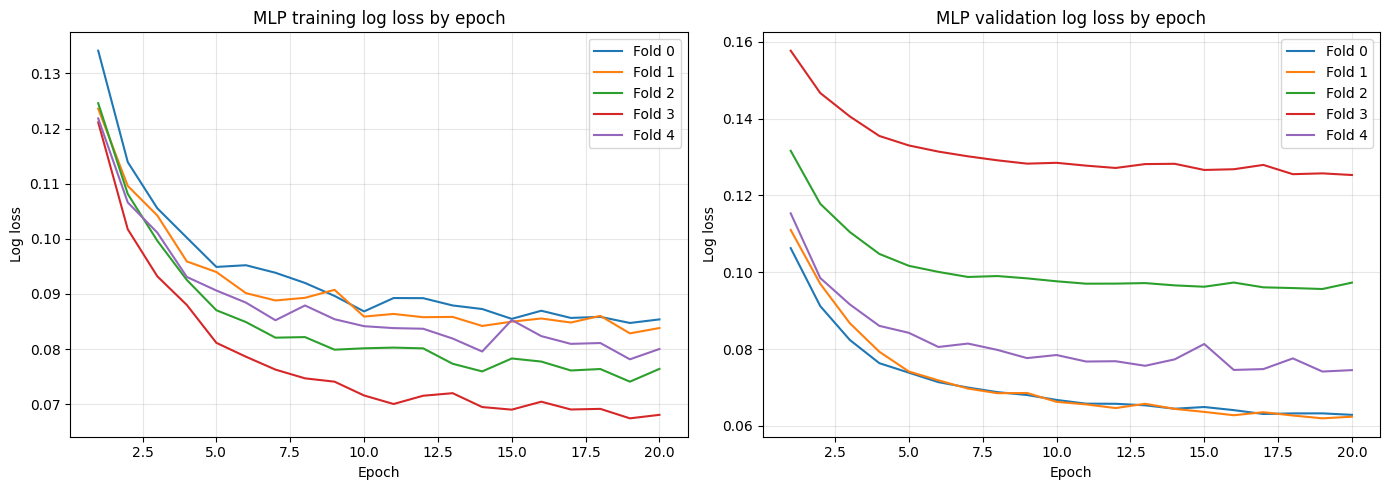

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for fold in sorted(cv_loss_history.fold.unique()):
    h = cv_loss_history[cv_loss_history.fold == fold]
    axes[0].plot(h.epoch, h.train_log_loss, label=f"Fold {fold}")
    axes[1].plot(h.epoch, h.val_log_loss, label=f"Fold {fold}")

axes[0].set_title("MLP training log loss by epoch")
axes[1].set_title("MLP validation log loss by epoch")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Log loss")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 10. Fit the final MLP using the training partition

After cross-validation, fit a final model using the training partition only. The student-test partition is not used for fitting, preprocessing or epoch selection.

The row cap is configurable and saved in the experiment configuration. For the final reported run, state whether the model used all valid training candidate rows or a sampled subset.

In [18]:
final_train = sample_training_rows(
    train_df, MAX_FINAL_TRAIN_ROWS, seed=SEED
)
y_final = final_train["label"].astype(int).to_numpy()
if len(np.unique(y_final)) != 2:
    raise ValueError("Final training data must contain both classes.")

final_scaler, final_medians, X_final = fit_preprocessor(final_train)
final_model = make_mlp(SEED)
rng = np.random.default_rng(SEED)
final_history_rows = []

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    order = rng.permutation(len(y_final))
    for start in range(0, len(order), BATCH_SIZE):
        idx = order[start:start+BATCH_SIZE]
        if epoch == 1 and start == 0:
            final_model.partial_fit(X_final[idx], y_final[idx], classes=np.array([0, 1]))
        else:
            final_model.partial_fit(X_final[idx], y_final[idx])

    sample_n = min(len(y_final), 100_000)
    sample_idx = rng.choice(len(y_final), size=sample_n, replace=False)
    p_train = predict_in_batches(final_model, X_final[sample_idx])
    final_history_rows.append({
        "epoch": epoch,
        "train_log_loss": log_loss(y_final[sample_idx], p_train, labels=[0, 1])
    })

final_training_seconds = time.time() - t0
final_loss_history = pd.DataFrame(final_history_rows)
print(f"Final model training time: {final_training_seconds:.1f} seconds")
display(final_loss_history.tail())

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is go

Final model training time: 75.9 seconds


,epoch,train_log_loss
15,16,0.082341
16,17,0.079365
17,18,0.079748
18,19,0.078890
19,20,0.077626


## 11. Evaluate on `student_test`

This is development-stage evaluation only. The final model and its preprocessing were fitted using `train` trips only.

We call the repository's `evaluate_predictions`, which reports:
- Candidate-level accuracy, precision, recall, macro F1 and log loss
- Observation-level Top-1 accuracy
- Candidate miss rate, using the fix table
- Classifier-only route continuity

In [19]:
student_prob = None
student_X = transform_features(student_df, final_scaler, final_medians)

t0 = time.time()
student_prob = predict_in_batches(final_model, student_X)
student_inference_seconds = time.time() - t0

student_metrics = evaluate_predictions(
    student_df, student_prob, fixes_student
)
student_metrics["inference_time_sec"] = float(student_inference_seconds)
n_student_fixes = fixes_student[["trip_id", "fix_idx"]].drop_duplicates().shape[0]
student_metrics["inference_ms_per_1000_fixes"] = (
    student_inference_seconds * 1000.0 / max(n_student_fixes, 1) * 1000.0
)

print(json.dumps(student_metrics, indent=2))

{
  "accuracy": 0.9728072310430894,
  "precision": 0.8649103747963064,
  "recall": 0.8321835476115815,
  "macro_f1": 0.9166485581107457,
  "log_loss": 0.06884865575727002,
  "tn": 187920,
  "fp": 2487,
  "fn": 3211,
  "tp": 15923,
  "top1": 0.8570234550488429,
  "candidate_miss_rate": 0.000522384161312229,
  "n_valid_fixes": 19143,
  "n_fixes": 19160,
  "route_continuity": 0.9465796344647519,
  "inference_time_sec": 0.4462404251098633,
  "inference_ms_per_1000_fixes": 23.290210078802886
}


## 12. Save the MLP experiment outputs

Outputs follow the repository's structure under `results/models/mlp/`. The fitted artifact is saved separately as `artifacts/mlp_model.joblib`; it does not overwrite Joshua's shared `artifacts/model.joblib`, because the final model has not yet been selected by the team.

The saved artifact contains the fitted MLP, fitted scaler, training medians and ordered feature list. These are all required to reproduce probabilities at inference time.

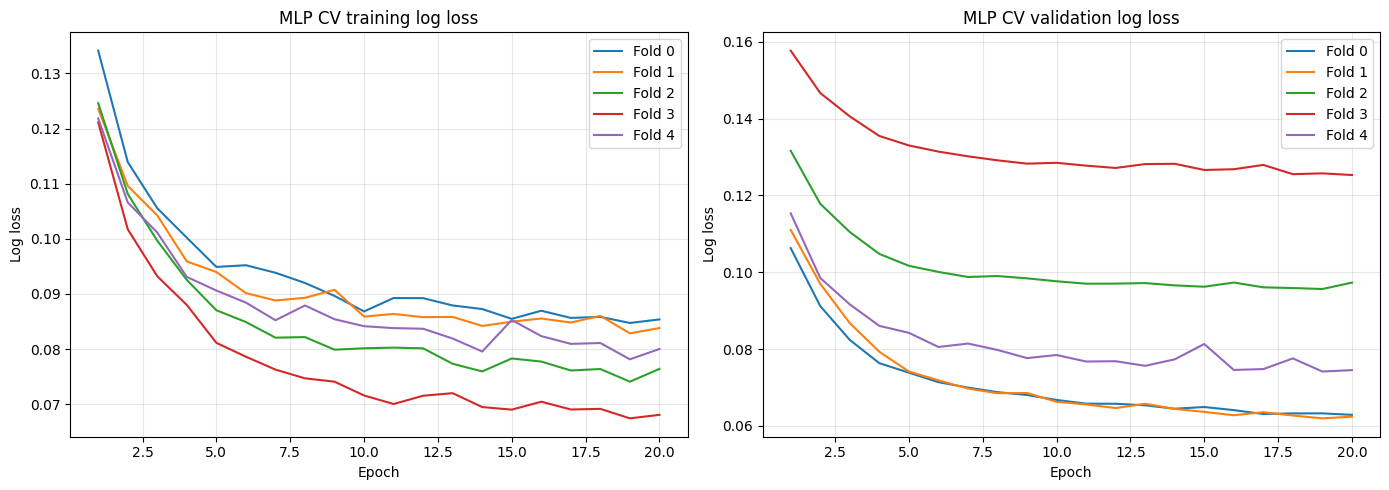

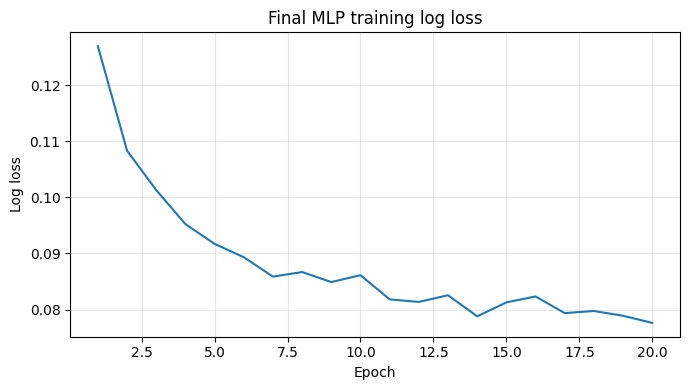

Saved:
 - results/models/mlp/config.json
 - results/models/mlp/cv_folds.csv
 - results/models/mlp/cv_loss_curves.png
 - results/models/mlp/final_loss_history.csv
 - results/models/mlp/final_training_loss.png
 - results/models/mlp/loss_history_cv.csv
 - results/models/mlp/student_test_metrics.json
 - artifacts/mlp_model.joblib


In [20]:
OUT_DIR = ROOT / "results" / "models" / "mlp"
ART_DIR = ROOT / "artifacts"
OUT_DIR.mkdir(parents=True, exist_ok=True)
ART_DIR.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(OUT_DIR / "cv_folds.csv", index=False)
cv_loss_history.to_csv(OUT_DIR / "loss_history_cv.csv", index=False)
final_loss_history.to_csv(OUT_DIR / "final_loss_history.csv", index=False)

with open(OUT_DIR / "student_test_metrics.json", "w") as f:
    json.dump(student_metrics, f, indent=2)

experiment_config = {
    "model": "MLPClassifier",
    "model_id": "mlp",
    "family": "neural_network",
    "owner": "Julia",
    "seed": SEED,
    "n_folds": N_FOLDS,
    "group_column": "trip_id",
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "hidden_layer_sizes": list(HIDDEN_LAYERS),
    "activation": "relu",
    "solver": "adam",
    "learning_rate_init": LEARNING_RATE,
    "alpha": ALPHA,
    "max_train_rows_per_fold": MAX_TRAIN_ROWS_PER_FOLD,
    "max_final_train_rows": MAX_FINAL_TRAIN_ROWS,
    "feature_columns": FEATURE_COLUMNS,
    "n_final_training_rows": int(len(final_train)),
    "n_training_trips": int(final_train.trip_id.nunique()),
    "final_training_time_sec": float(final_training_seconds),
    "student_test_metrics": student_metrics,
    "preprocessing": "Median imputation and StandardScaler fitted on training data only."
}
with open(OUT_DIR / "config.json", "w") as f:
    json.dump(experiment_config, f, indent=2)

artifact = {
    "model": final_model,
    "scaler": final_scaler,
    "medians": final_medians.to_dict(),
    "feature_columns": FEATURE_COLUMNS,
    "config": experiment_config
}
joblib.dump(artifact, ART_DIR / "mlp_model.joblib")

# Save figures as reproducible report artifacts.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for fold in sorted(cv_loss_history.fold.unique()):
    h = cv_loss_history[cv_loss_history.fold == fold]
    axes[0].plot(h.epoch, h.train_log_loss, label=f"Fold {fold}")
    axes[1].plot(h.epoch, h.val_log_loss, label=f"Fold {fold}")
axes[0].set_title("MLP CV training log loss")
axes[1].set_title("MLP CV validation log loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Log loss")
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "cv_loss_curves.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(final_loss_history.epoch, final_loss_history.train_log_loss)
ax.set_title("Final MLP training log loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Log loss")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "final_training_loss.png", dpi=160, bbox_inches="tight")
plt.show()

print("Saved:")
for p in sorted(OUT_DIR.iterdir()):
    print(" -", p.relative_to(ROOT))
print(" -", (ART_DIR / "mlp_model.joblib").relative_to(ROOT))

## 13. Add the MLP result to the team's shared comparison

The uploaded repository snapshot has `src/evaluate.py` but does not yet have `src/model_zoo.py` or `src/train.py`. The notebook therefore does not create replacement versions of those files.

After this notebook finishes:
1. Share `results/models/mlp/config.json`, `cv_folds.csv`, `student_test_metrics.json` and loss plots with the team.
2. Coordinate with Krishna so the MLP is included in the single shared `results/models/model_comparison.csv`.
3. Register the MLP factory in `src/model_zoo.py` once that file exists, following the actual interface the team agrees on.
4. Ensure the shared runner preserves epoch-by-epoch training and validation log-loss histories. A single `.fit()` call does not produce those curves.
5. Joshua should only incorporate `artifacts/mlp_model.joblib` into the final inference artifact if the team selects MLP as the final model.

Do not replace the shared `artifacts/model.joblib` with the MLP merely because this notebook ran successfully.

## 14. Final verification checklist

- [ ] Candidate and fix parquet files were generated by `src.build_dataset`.
- [ ] Features were generated by `src.features` and use the repository's `FEATURE_COLUMNS`.
- [ ] No `arc_id`, `trip_id`, `true_arc`, `label`, `fix_valid` or route-derived values were used as model inputs.
- [ ] GroupKFold split by `trip_id` was used for all five folds.
- [ ] Imputation and scaling were fitted on training data only in each fold.
- [ ] Invalid fixes were excluded from supervised fitting.
- [ ] Actual train and validation log loss were recorded at every epoch.
- [ ] Student-test data was used only for development evaluation.
- [ ] The row-sampling cap, if used, is reported transparently.
- [ ] Config, metrics, loss histories, plots and model artifact were saved.
- [ ] MLP results are added to the shared model comparison without overwriting other members' work.

### Interpretation for your report / viva

The MLP is one of the six candidate classifiers, not automatically the final selected model. Compare it with Logistic Regression, KNN, Gaussian Naive Bayes, Random Forest and XGBoost using the same features, trip-aware CV and metrics. Discuss the loss curves, generalisation, probability quality, inference cost and compatibility with the HMM.